# 01 · Data acquisition & EDA
UCI Heart Disease (Cleveland, 303 patients, 13 features + target).

Run `python scripts/download_data.py` first (or the cell below does it).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]
import os; os.chdir(ROOT)

In [2]:
import subprocess, pandas as pd
subprocess.run([sys.executable, "scripts/download_data.py"], check=True)
from heart.data import load_raw, build_clean_dataset, missing_report
raw = load_raw(); raw.head()

INFO Raw data already present at /Users/bmamidipalli/Library/CloudStorage/OneDrive-EvokeTechnologiesPrivateLimited/Claude/Projects/MLOps/heart-mlops/data/raw/heart_raw.csv (use --force to refresh)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Data quality
`ca` and `thal` contain `?` in the original file → NaN. They are **not** imputed here; imputation (median / mode) is part of the sklearn pipeline so statistics are learned on the training folds only.

In [3]:
print(raw.shape); print(raw.dtypes.value_counts()); missing_report(raw)

(303, 14)
float64    13
int64       1
Name: count, dtype: int64


ca      4
thal    2
dtype: int64

In [4]:
df = build_clean_dataset()
print("Positive rate:", round(df.target.mean(), 3)); df.describe().T.round(2)

Positive rate: 0.459


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
slope,303.0,1.60,0.62,1.0,1.0,2.0,2.0,3.0
ca,299.0,0.67,0.94,0.0,0.0,0.0,1.0,3.0
thal,301.0,4.73,1.94,3.0,3.0,3.0,7.0,7.0


## Visualisations

In [5]:
from heart import eda
summary = eda.run(); summary

{'rows': 303,
 'positive_rate': 0.459,
 'missing_raw': {'ca': 4, 'thal': 2},
 'top_correlations_with_target': {'thal': 0.526,
  'ca': 0.46,
  'exang': 0.432,
  'oldpeak': 0.425,
  'thalach': 0.417,
  'cp': 0.414}}

00_missing_values.png


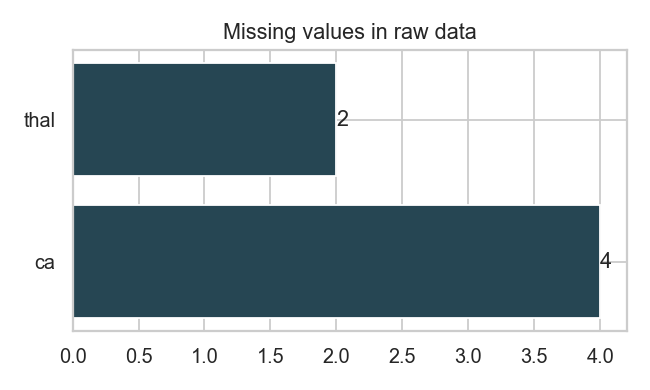

01_class_balance.png


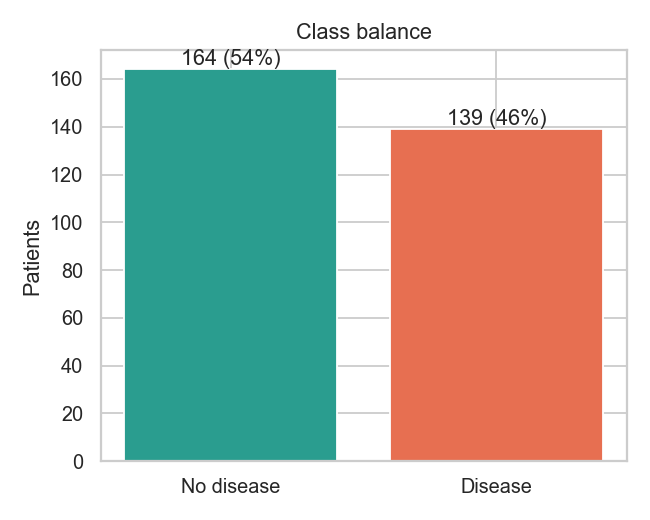

02_numeric_histograms.png


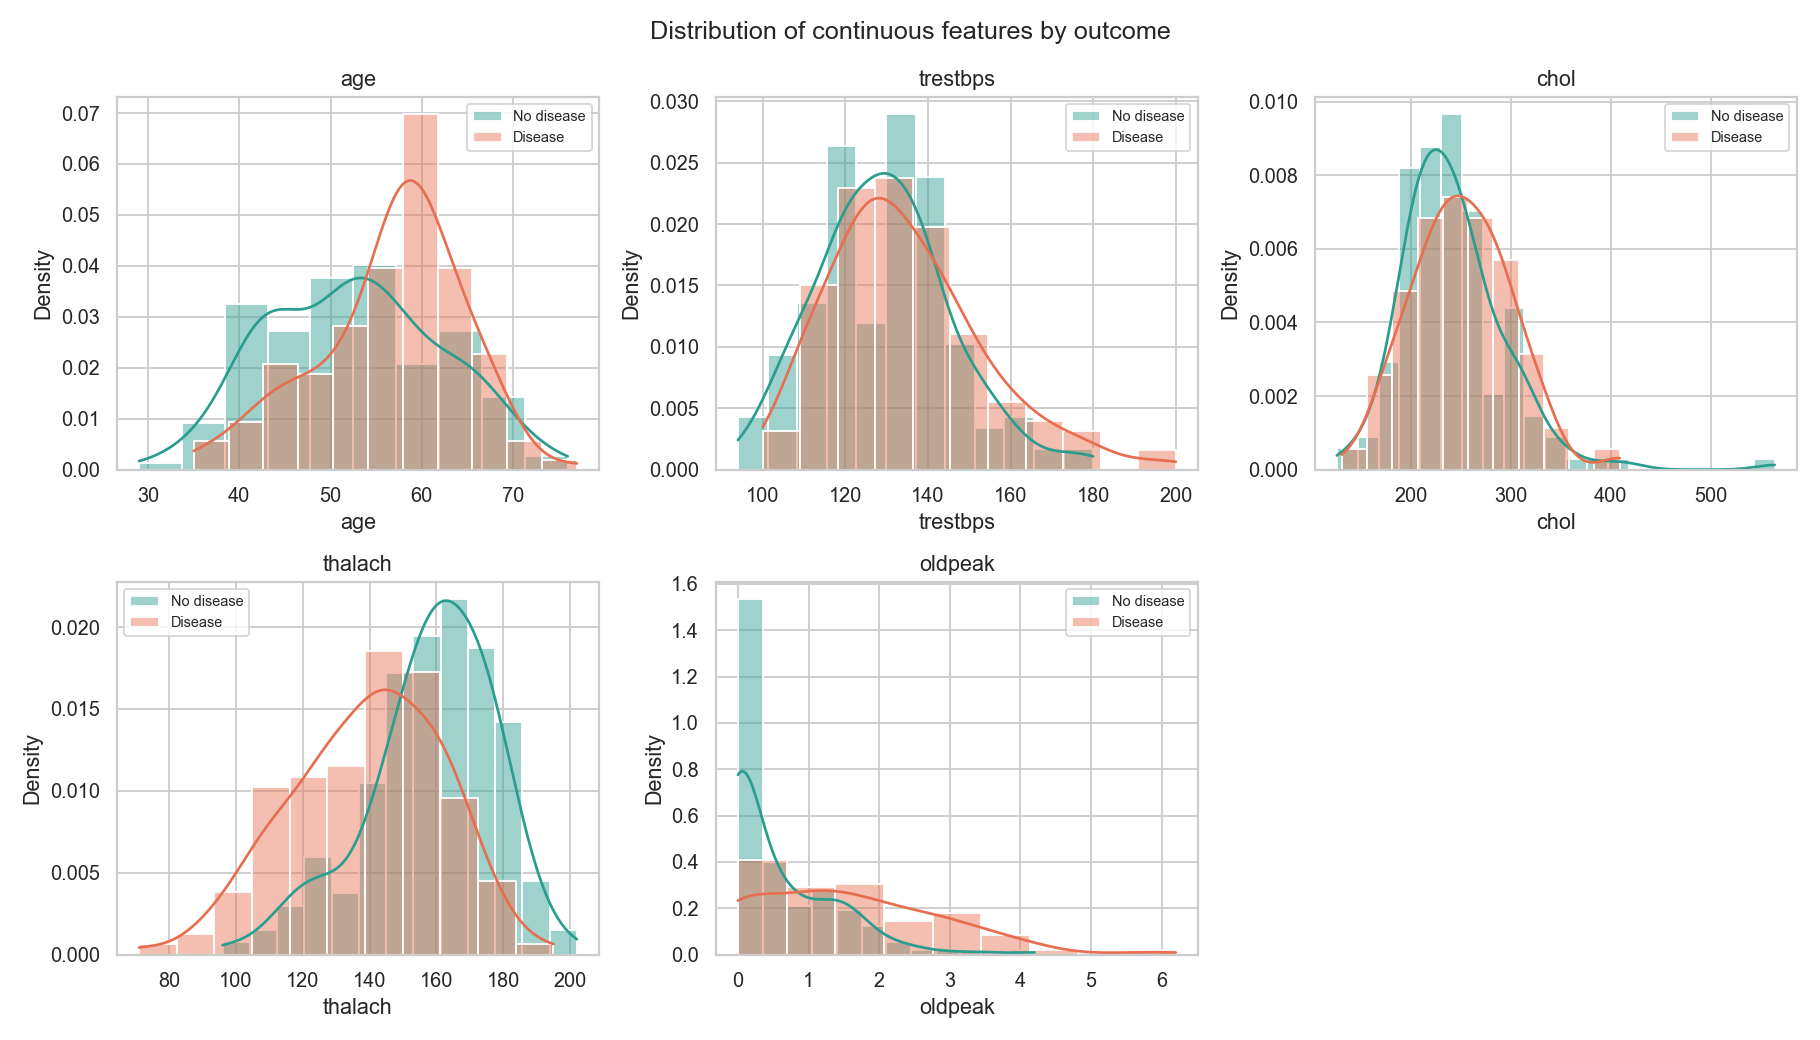

03_categorical_disease_rate.png


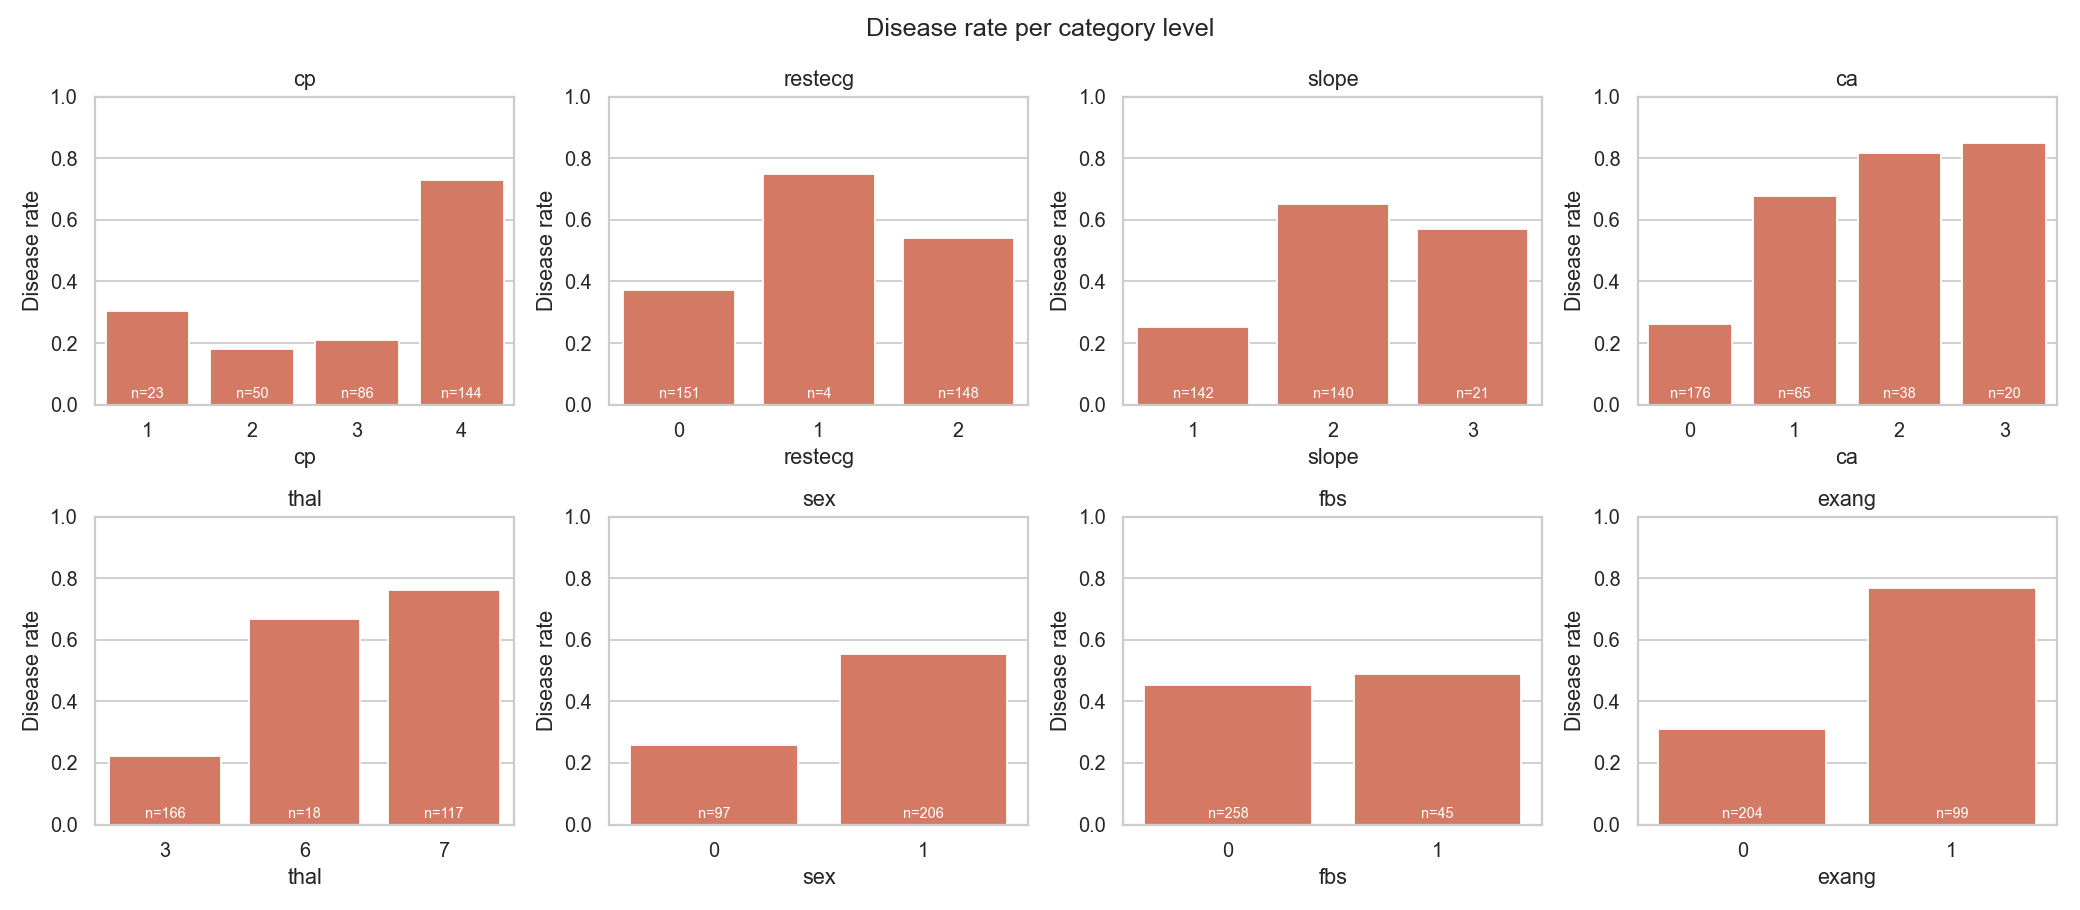

04_correlation_heatmap.png


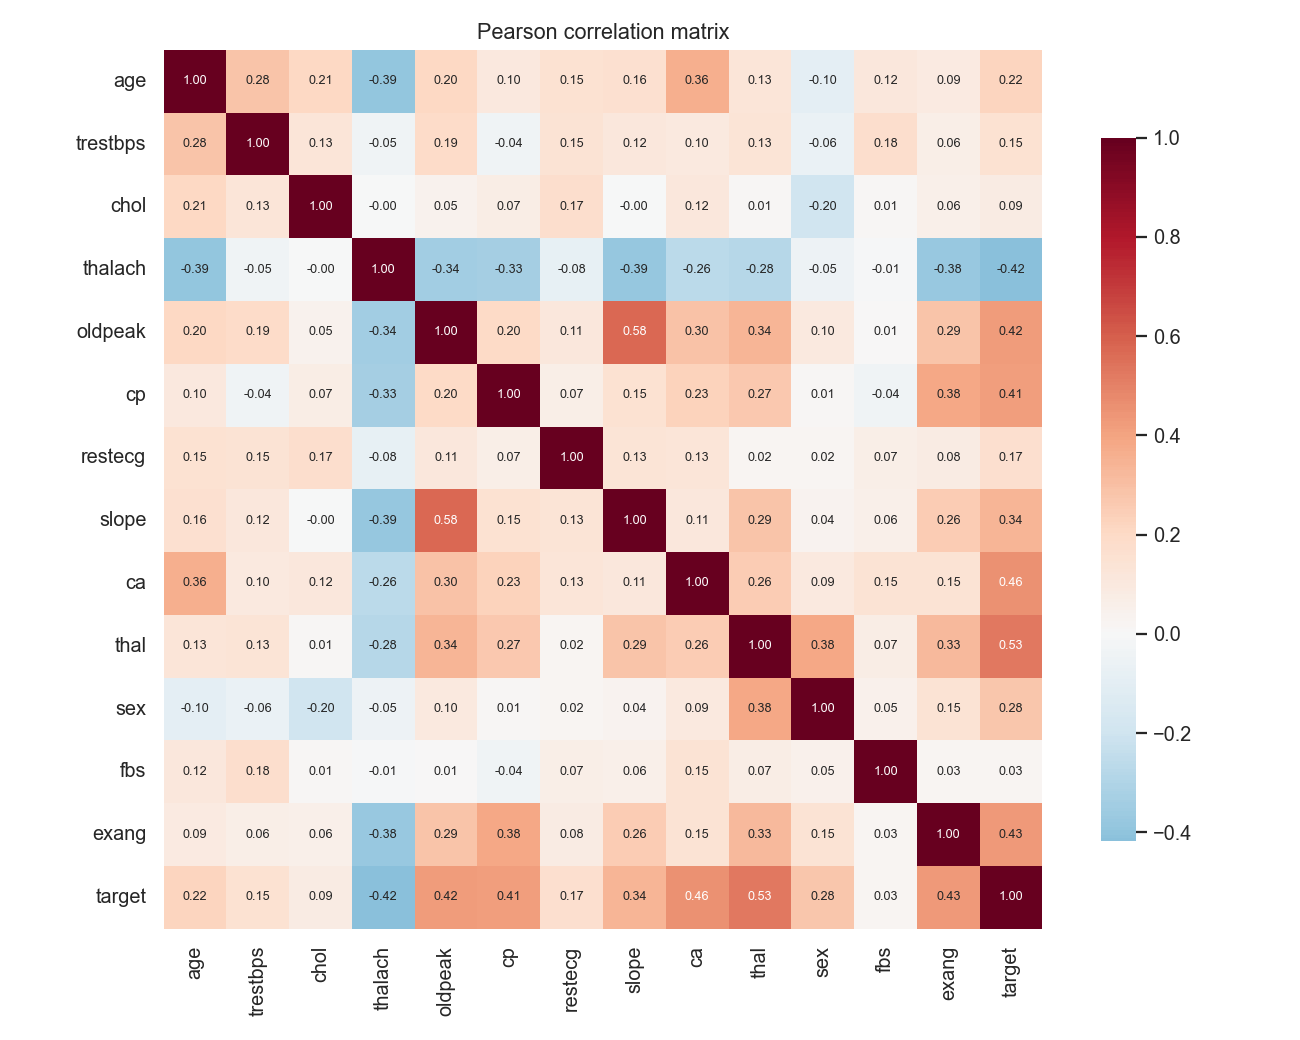

05_boxplots.png


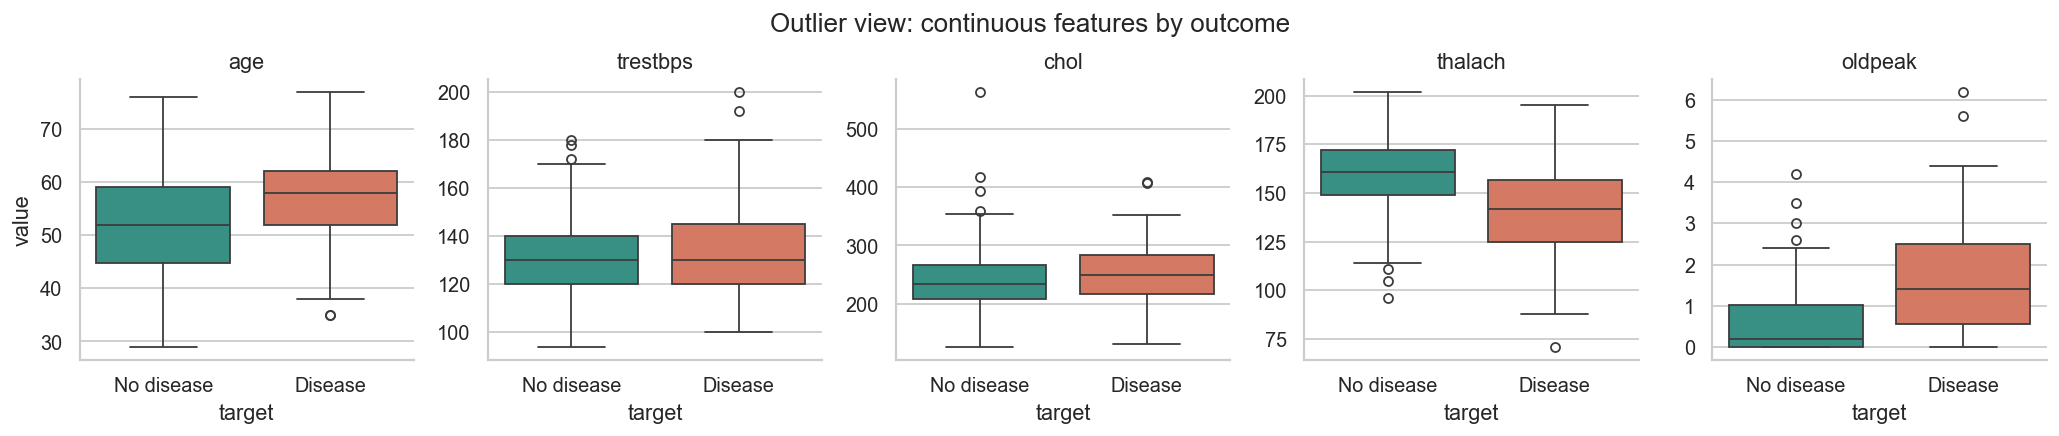

In [6]:
from IPython.display import Image, display
for f in sorted((ROOT/"reports/figures").glob("0*.png")):
    print(f.name); display(Image(filename=str(f)))

## Observations

- Only `ca` and `thal` have missing values: 4 and 2 respectively. I would keep these rows and let the pipeline learn imputation values from the training folds.
- There are 164 patients without disease and 139 with disease (45.9% positive). The classes are reasonably close in size, but I still need recall and precision to see what the model misses and how many positive predictions are wrong.
- The histograms and boxplots show lower `thalach` and higher `oldpeak` in the disease group. The heatmap agrees: their target correlations are about -0.42 and +0.42. Patients with disease also tend to be older, although the age distributions overlap.
- Disease rates are higher for `cp = 4`, `thal = 7`, exercise angina, and higher `ca` values. I would be careful with `restecg = 1`: its 75% disease rate comes from only four patients. Correlations for category codes are descriptive and depend on how those categories were numbered.
- Cholesterol and resting blood pressure overlap heavily between the two groups. Their boxplots also show high outliers, including cholesterol above 500 in the no-disease group. These measurements do not separate the groups well on their own, and an outlier is not automatically a bad record.
